In [2]:
import sys 
sys.path.append('/home/grace.bcolverd/2024-ESL-BiomassSAR')
from src.fdlbiomass.utils import read_biomass_data

In [5]:
# import numpy as np

# def read_biomass_data(full_path, crop_struct, data_type):
#     # Single precision size
#     N = 4

#     try:
#         with open(full_path, 'rb') as fid:
#             # Read total dimensions
#             NrTot = int(np.fromfile(fid, dtype='<f4', count=1)[0])
#             NcTot = int(np.fromfile(fid, dtype='<f4', count=1)[0])

#             if not crop_struct:
#                 crop_struct = {
#                     'S': NrTot, 'Sin': 1, 'Sfin': NrTot,
#                     'L': NcTot, 'Lin': 1, 'Lfin': NcTot
#                 }

#             if 'S' in crop_struct and 'L' in crop_struct:
#                 if NrTot != crop_struct['S'] or NcTot != crop_struct['L']:
#                     print(f"Warning: Dimension mismatch. Expected {crop_struct['S']}x{crop_struct['L']}, got {NrTot}x{NcTot}")

#             Nr = int(crop_struct['Sfin'] - crop_struct['Sin'] + 1)
#             Nc = int(crop_struct['Lfin'] - crop_struct['Lin'] + 1)

#             if data_type == 1:  # Complex
#                 fid.seek(2*N + ((crop_struct['Lin'] - 1)*NrTot + crop_struct['Sin'] - 1)*N*2)
                
#                 if crop_struct['Sin'] == 1 and crop_struct['Sfin'] == NrTot:
#                     I = np.fromfile(fid, dtype='<f4', count=2*Nr*Nc).reshape(2*Nr, Nc, order='F')
#                 else:
#                     I = np.zeros((2*Nr, Nc), dtype='<f4')
#                     for i in range(Nc):
#                         I[:, i] = np.fromfile(fid, dtype='<f4', count=2*Nr)
#                         fid.seek((NrTot - crop_struct['Sfin'] + crop_struct['Sin'] - 1)*N*2, 1)
                
#                 I = I[0::2] + 1j*I[1::2]

#             elif data_type == 2:  # Real
#                 fid.seek(2*N + ((crop_struct['Lin'] - 1)*NrTot + crop_struct['Sin'] - 1)*N)
                
#                 if crop_struct['Sin'] == 1 and crop_struct['Sfin'] == NrTot:
#                     I = np.fromfile(fid, dtype='<f4', count=Nr*Nc).reshape(Nr, Nc, order='F')
#                 else:
#                     I = np.zeros((Nr, Nc), dtype='<f4')
#                     for i in range(Nc):
#                         I[:, i] = np.fromfile(fid, dtype='<f4', count=Nr)
#                         fid.seek((NrTot - crop_struct['Sfin'] + crop_struct['Sin'] - 1)*N, 1)

#             else:
#                 print("Error: Unrecognized data type.")
#                 return None

#     except IOError:
#         print(f"Error: Cannot open file {full_path}")
#         return None

#     return I

The script processes P-band Synthetic Aperture Radar (SAR) data by first setting up the directory paths and defining parameters like the heading direction and polarimetric channel. It loads various datasets including scene parameters, phase-to-height factors (kz), sensor trajectories, and digital terrain models (DTMs). Single Look Complex (SLC) images for the specified polarimetric channel are read and processed. The script performs repeat-pass tomography to generate and visualize tomographic profiles in both the azimuth and ground range directions. Additionally, it reads ancillary geocoding data from MetaSensing files and adjusts the data to match the scene parameters.

Comments on Changes or Uncertainties:
- Function Placeholder: The read_biomass_data function needs to be implemented based on the actual data format. This placeholder assumes it handles the reading of SLC and other data formats.
- Path Handling: Paths are constructed using os.path.join for better cross-platform compatibility.
- Polarimetric Index: Adjusted to 0-based indexing in Python as opposed to 1-based indexing in MATLAB.
- Scene Parameters: Loaded using scipy.io.loadmat to read .mat files.
- Tomographic Processing: Adjustments for handling complex numbers and numpy operations.
- Geocoding Data: Ancillary data from NetCDF files is read using the netCDF4 library, and indices are calculated to slice this data to match the scene parameters.

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat
from netCDF4 import Dataset


# Change directory to parent folder and set paths
os.chdir('..')
parent_path = '/home/grace.bcolverd/P'


# Define heading and polarimetric channel
heading = 'NW'  # Either 'NW' (290°) or 'SE' (110°)
polarimetric_channel = 'HH'  # 'HH', 'HV' or 'VV'

# Determine the polarimetric index based on the channel
if polarimetric_channel == 'HH':
    pol_ind = 1
elif polarimetric_channel == 'HV':
    pol_ind = 2
elif polarimetric_channel == 'VV':
    pol_ind = 3

# Loading

# Loading scene parameters
curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'SceneParameters.mat')
scene_parameters = loadmat(curr_fullpath)

ground_range_axis = scene_parameters['ground_range_axis'].squeeze()
azimuth_axis = scene_parameters['azimuth_axis'].squeeze()
Ngr = len(ground_range_axis)
Naz = len(azimuth_axis)

# Loading phase-to-height factors
kz = np.zeros((Ngr, Naz, scene_parameters['N'][0][0]), dtype=np.single)
for n in range(scene_parameters['N'][0][0]):
    # Ensure the filename is treated as a string
    filename_kz = scene_parameters['filenames_kz'][n][0]
    if isinstance(filename_kz, np.ndarray):
        filename_kz = str(filename_kz[0])  # Convert ndarray to string, assuming the actual string is the first element
    curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'kz', filename_kz)
    print(f'Loading {curr_fullpath}...')
    kz[:, :, n] = read_biomass_data(curr_fullpath, [], 2)
    print('done.')


# Loading sensor trajectories
curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'FocusingCenters.mat')
focusing_centers = loadmat(curr_fullpath)

# Loading DTMs
curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'MetaSensingDTM.mat')
meta_sensing_dtm = loadmat(curr_fullpath)
curr_fullpath = os.path.join(parent_path, heading, 'Util', 'SLC', 'TomoDTMsr.mat')
tomo_dtm_sr = loadmat(curr_fullpath)

# Loading SLC images
I = np.zeros((Ngr, Naz, scene_parameters['N'][0][0]), dtype=np.complex64)


for n in range(scene_parameters['N'][0][0]):
    curr_fullpath = os.path.join(parent_path, heading, 'SLC', 'PoliMi', scene_parameters['filenames_slc'][n, pol_ind-1][0])
    print(f'Loading {curr_fullpath}...')
    I[:, :, n] = read_biomass_data(curr_fullpath, [], 1)

    print('done.')


Loading /home/grace.bcolverd/P/NW/Util/SLC/kz/kz_20200722071511_435.0M_HH_12_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/P/NW/Util/SLC/kz/kz_20200722072647_435.0M_HH_12_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/P/NW/Util/SLC/kz/kz_20200722073834_435.0M_HH_12_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/P/NW/Util/SLC/kz/kz_20200722075104_435.0M_HH_12_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/P/NW/Util/SLC/kz/kz_20200722080252_435.0M_HH_12_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/P/NW/Util/SLC/kz/kz_20200722081445_435.0M_HH_12_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/P/NW/Util/SLC/kz/kz_20200722082619_435.0M_HH_12_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/P/NW/Util/SLC/kz/kz_20200722083752_435.0M_HH_12_pres_16_fdc_0.sar.sig.nc.dat...
done.
Loading /home/grace.bcolverd/P/NW/Util/SLC/kz/kz_20200722084916_435.0M_HH_12_pre

In [4]:
scene_parameters['N'][0][0]

28

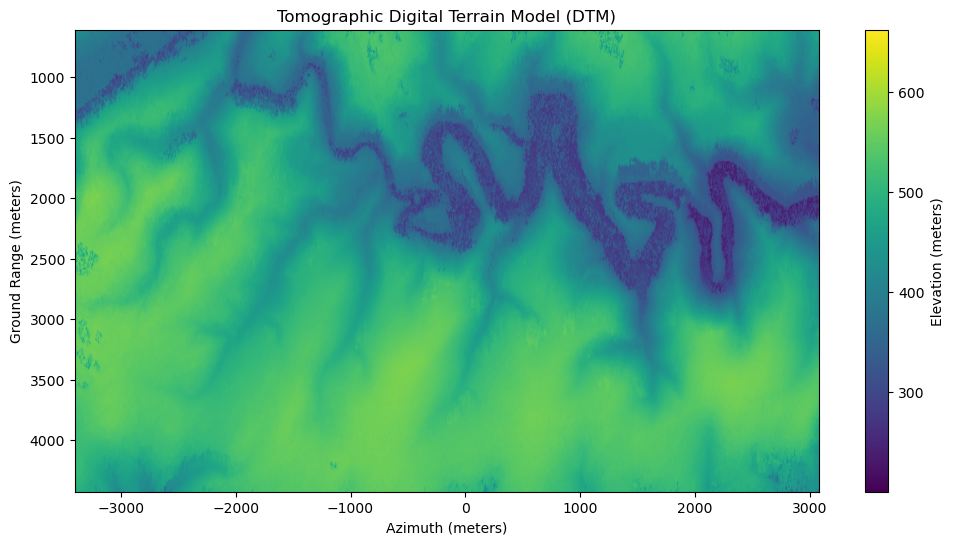

In [3]:
# Extract the azimuth and ground range values from their axis matrices
azimuth_values = tomo_dtm_sr['azimuth_axis'].flatten()  # Flatten to make 1D for plotting
ground_range_values = tomo_dtm_sr['ground_range_axis'].flatten()

# Plotting the entire Tomographic DTM
plt.figure(figsize=(12, 6))
plt.imshow(tomo_dtm_sr['TomoDTMsr'], aspect='auto', extent=[azimuth_values.min(), azimuth_values.max(), ground_range_values.max(), ground_range_values.min()], origin='lower')
plt.colorbar(label='Elevation (meters)')
plt.xlabel('Azimuth (meters)')
plt.ylabel('Ground Range (meters)')
plt.title('Tomographic Digital Terrain Model (DTM)')
plt.show()

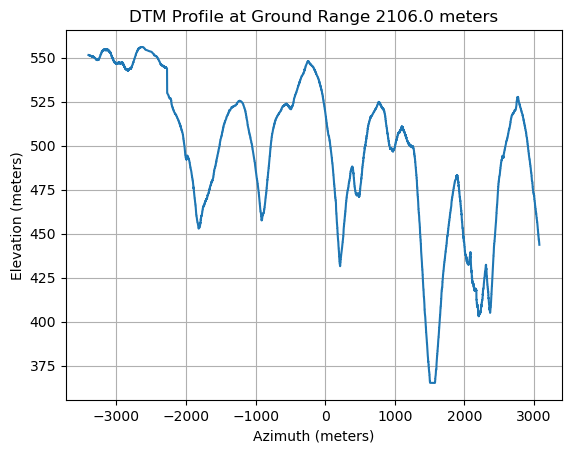

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Example: Visualizing a slice of the DTM data across all azimuths at a specific ground range index
gr_ind = 500  # A specific ground range index
dtm_slice = meta_sensing_dtm['MetaSensingDTM'][gr_ind, :].squeeze()  # Squeeze to remove single-dimensional entries

azimuth_values = meta_sensing_dtm['azimuth_axis'].squeeze()  # Squeeze to make it a 1D array
ground_range_value = meta_sensing_dtm['ground_range_axis'][gr_ind, 0]  # Single ground range value

plt.figure()
plt.plot(azimuth_values, dtm_slice)
plt.title(f'DTM Profile at Ground Range {ground_range_value} meters')
plt.xlabel('Azimuth (meters)')
plt.ylabel('Elevation (meters)')
plt.grid(True)
plt.show()


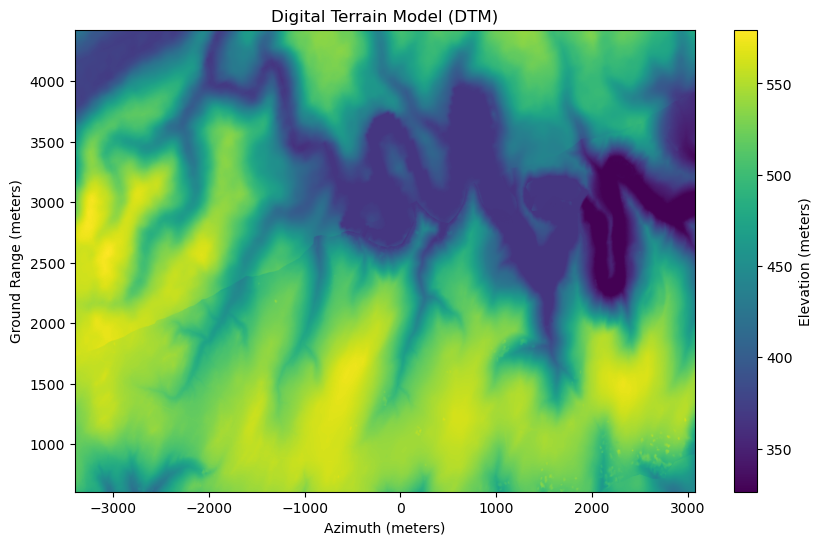

In [5]:
plt.figure(figsize=(10, 6))
plt.imshow(meta_sensing_dtm['MetaSensingDTM'], aspect='auto', extent=[azimuth_values.min(), azimuth_values.max(), meta_sensing_dtm['ground_range_axis'].min(), meta_sensing_dtm['ground_range_axis'].max()], origin='lower')
plt.colorbar(label='Elevation (meters)')
plt.xlabel('Azimuth (meters)')
plt.ylabel('Ground Range (meters)')
plt.title('Digital Terrain Model (DTM)')
plt.show()


In [6]:
gr_ind = round(Ngr/4)
kz[gr_ind, :, :].shape

(12953, 28)

In [9]:
I.shape

(1274, 12953, 28)

I shape: (1274, 12953, 28)
kz shape: (1274, 12953, 28)
TomoDTMsr shape: (1274, 12953)
MetaSensingDTM shape: (1274, 12953)
F shape: (12953,)
[0.04167349 0.09284282 0.12392019 ... 4.3905816  3.4761431  2.569966  ]
dtm  (12953,)
exp term  (12953, 28)
S shape: (121, 12953)


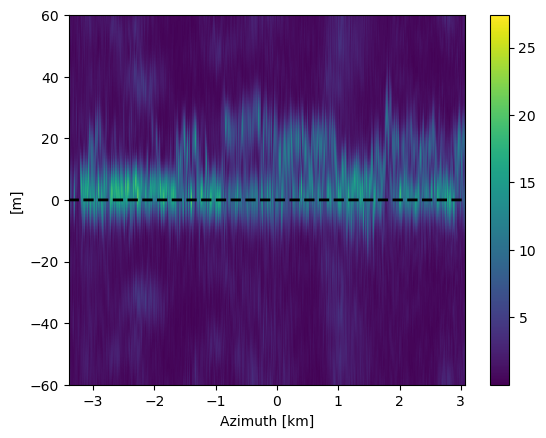

In [8]:

Naz = I.shape[1]
Ngr = I.shape[0]

print(f"I shape: {I.shape}")
print(f"kz shape: {kz.shape}")
print(f"TomoDTMsr shape: {tomo_dtm_sr['TomoDTMsr'].shape}")
print(f"MetaSensingDTM shape: {meta_sensing_dtm['MetaSensingDTM'].shape}")

# Local vertical axis (with respect to the local ground level)
z_axis = np.arange(-60, 61)
Nz = len(z_axis)

# Azimuth profile
S = np.zeros((Nz, Naz))
# why is ground index defined this way? is it random? 
gr_ind = round(Ngr/4)
# normalisation term ? shoud this be 2 x 2 or 1d array - unclear from matlab code - sum over 3rd dim that does not exist? sum over z axis?  single value for each azimuth 
F = np.sum(np.abs(I[gr_ind, :, :])**2, axis=1)

# F = np.abs(I[gr_ind, :, :])**2
print(f"F shape: {F.shape}")
print(F)
# Ground steering
# height diff between two dtms for the given ground index     , across whole azimuth length 
dtm_diff = (tomo_dtm_sr['TomoDTMsr'][gr_ind, :] - meta_sensing_dtm['MetaSensingDTM'][gr_ind, :])
print('dtm ' , dtm_diff.shape)
# this kz[gr_ind, :, :] selects the corresponding vertical wavenumbers for the ground range index for all azimuth, then mult the  vertical wavenumbers by the height difference for each azimuth, creating a phase correction term.
exp_term = np.exp(-1j * kz[gr_ind, :, :] * dtm_diff[:, np.newaxis])
print('exp term ' , exp_term.shape)
# this selects a slice of the complex SAR image data I for gr_ind, all elements along the azimuth and tomographic dimensions for this ground range. mult by exp term (exp has all azimuth and all z for one gr ind) 
Igs = I[gr_ind, :, :] * exp_term

for z_ind in range(Nz):
    z = z_axis[z_ind]

    # This creates a complex exponential term for a specific height z, a  focusing term,  , used to "focus" the ground-steered data (Igs) to that height. 
    exp_z_term = np.exp(-1j * kz[gr_ind, :, :] * z)
    # print('exp z term ' , exp_z_term.shape)
    #  representing the sum for each azimuth position of the  ground-steered image data with exp z term 
    sum_term = np.sum(Igs * exp_z_term, axis=1)

    # np.abs(sum_term)**2 computes the squared magnitude of the complex values.   
    S[z_ind, :] = np.abs(sum_term)**2 / (F + np.finfo(float).eps)

# The result S represents the intensity of the backscattered signal at height z for each azimuth position.
print(f"S shape: {S.shape}")

plt.figure()
plt.imshow(S, extent=[meta_sensing_dtm['azimuth_axis'][0, 0]*1e-3, meta_sensing_dtm['azimuth_axis'][0, -1]*1e-3, z_axis[0], z_axis[-1]],  aspect='auto',origin = 'lower')
plt.colorbar()
plt.xlabel('Azimuth [km]')
plt.ylabel('[m]')
plt.plot(meta_sensing_dtm['azimuth_axis'][0]*1e-3, np.zeros(Naz), '--k', linewidth=2)
plt.show()

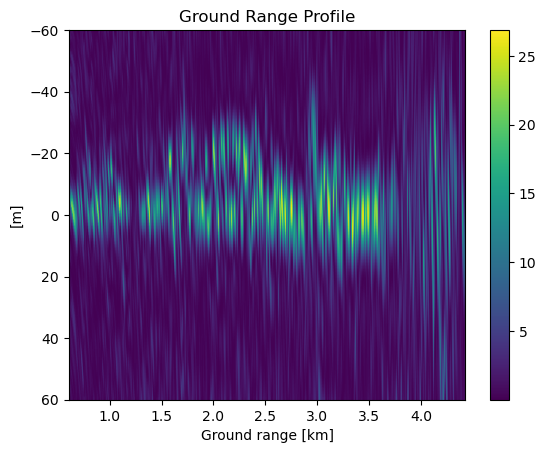

In [9]:
# Ground range profile
S = np.zeros((Nz, Ngr))
az_ind = round(Naz / 3)
F = np.sum(np.abs(I[:, az_ind, :])**2, axis=1)

for z_ind in range(Nz):
    z = z_axis[z_ind]

    # Calculate DTM differences and reshape for broadcasting
    dtm_diff = (tomo_dtm_sr['TomoDTMsr'][:, az_ind] -  meta_sensing_dtm['MetaSensingDTM'][:, az_ind])[:, np.newaxis]

    # Ground steering
    Igs = I[:, az_ind, :] * np.exp(-1j * kz[:, az_ind, :] * dtm_diff)

    # Correct the axis parameter in the summation to match the dimensions of Igs
    S[z_ind, :] = np.abs(np.sum(Igs * np.exp(-1j * kz[:, az_ind, :] * z), axis=1))**2 / (F + np.finfo(float).eps)

plt.figure()
plt.imshow(S, aspect='auto', extent=[ground_range_axis[0]*1e-3, ground_range_axis[-1]*1e-3, z_axis[-1], z_axis[0]], origin='lower')
plt.xlabel('Ground range [km]')
plt.ylabel('[m]')
plt.title('Ground Range Profile')
plt.colorbar()
plt.show()


In [10]:
import os
import numpy as np
from netCDF4 import Dataset

# Reading MetaSensing ancillary data
if heading == 'NW':
    curr_fullpath = os.path.join(parent_path, heading, 'SLC', 'MetaSensing', 'SAR_CPLX_20200722092915_435.0M_HH_12_pres_16_fdc_0.sar.sig.nc')
elif heading == 'SE':
    curr_fullpath = os.path.join(parent_path, heading, 'SLC', 'MetaSensing', 'SAR_CPLX_20200723082647_435.0M_HH_12_pres_16_fdc_0.sar.sig.nc')

# Open the netCDF file
with Dataset(curr_fullpath, 'r') as nc:
    LatImage_azimuth_axis = nc.variables['CrossRange'][:]
    LatImage_ground_range_axis = nc.variables['GroundRange'][:]
    LatImage = nc.variables['LatImage'][:]

# Find start and stop indices
az_start_ind = np.argmin(np.abs(LatImage_azimuth_axis - azimuth_axis[0]))
az_stop_ind = np.argmin(np.abs(LatImage_azimuth_axis - azimuth_axis[-1]))
gr_start_ind = np.argmin(np.abs(LatImage_ground_range_axis - ground_range_axis[0]))
gr_stop_ind = np.argmin(np.abs(LatImage_ground_range_axis - ground_range_axis[-1]))

# Slice LatImage
LatImage = LatImage[gr_start_ind:gr_stop_ind+1, az_start_ind:az_stop_ind+1]

In [11]:
LatImage

masked_array(
  data=[],
  mask=False,
  fill_value=1e+20,
  dtype=float64)